# Лабораторная работа 3

Простейшее решение логистической задачи планирования.

**Цель:** создать агентов заказов и курьеров, которые строят расписание через переговоры. Выполнены три задания самостоятельной работы: три типа действий, поиск пересечений и эксперимент на 50 заказах и 20 курьерах.

Запускайте ячейки сверху вниз. В notebook приведен полный код, отдельные `.py` не требуются. Зависимости: `pip install thespian pandas openpyxl`. Исходный Excel встроен ниже; при наличии файла рядом используется он. Это учебные данные на три заказа и три курьера, а не файл эталонного репозитория.

## 1 Чтение исходных данных

Excel содержит листы «Заказы» и «Курьеры». Имена столбцов соответствуют методичке. Время и стоимость заданы в условных единицах. Следующая ячейка восстанавливает встроенный файл, только если его еще нет.

In [1]:
from pathlib import Path
import base64
import logging

Path('Отчёты').mkdir(exist_ok=True)
input_bytes = base64.b64decode('UEsDBBQAAAAIAKkAVl2SCoxT9gAAAL4BAAAPAAAAeGwvd29ya2Jvb2sueG1stdGxTsMwEAbgV7FuJ65DSdOobhcWVt7Acc6N1diObBcyVmKEHYmn6IKQeArnjRAFEVUsLGyn+6XTp/9Wm8F05A590M5yYNkMCFrpGm23HPZRXZSwWa+G6t75Xe3cjgyms6EaOLQx9hWlQbZoRMhcj3YwnXLeiBgy57c09B5FE1rEaDqaz2YFNUJb+Lx32oafiVhhkEN6Tsf0no7pbXwEckpuGg4MiK90w+G2XBaK1XkpZLOYL9gSvj3+Lx6nlJZ47eTeoI1fII+diNrZ0Oo+AKG/RC/jw3gYn9LreDgz5ZPpsshzxeqrUrJ5WeA/mOhUGJ1+sf4AUEsDBBQAAAAIAKkAVl0hXzspuQEAAFkHAAANAAAAeGwvc3R5bGVzLnhtbNVVTU/jMBD9K5bvNE1XVKsKg1hEJC5c4LBXJ5mklsYfsl1w99evbOeLSgi6p61yyJsnvzczcTy+uQsSyRtYJ7RitFytKQHV6FaontGD765+0rvbm7Bz/ojwsgfwJEhUbhcY3XtvdkXhmj1I7lbagAoSO20l926lbV84Y4G3LsokFpv1eltILhSNjp1W3pFGH5Rn9MdEpWR/yBtHRsuSkiISikvI1AO3KLxOfDErvqG8t4LjZ7o6rz5PPgCXjATiaTcCMb4N9x6sqgQiGfDr0QCjSiuYHIfFX4p6y4/l5vpsndMo2lxX/6BRW2L7mtGqetzGZ/Rb6Bf+A0id1tq2YKdeSzqTESF0Pn87K/r9AL02GdTaey0zbgXvteI4ZB4tJpiyNYD4Ev+9391JytARdZCV9E8to2tK4laMUCAOMFsNQU60tBxTLNy3/+oeujnN5wblNwy4MXh8PsgabJVOU5IlttJqGQnEOfqVzFL8H5SQ4nsUvZIw7xofiTh0vGji0WpAebDj9oTuEmt/t9y8QsjmZzayuehGNpfVSDEd+A/j5WS4TDyJNwCjz7Fq/HjGl6PEpXC+JG//AlBLAwQUAAAACACqAFZd+lwBWQMDAADaDQAAEwAAAHhsL3RoZW1lL3RoZW1lMS54bWy9V9tymzAU/BVG7w03c/OEZBLHbh/SaafJD8ggQI0QHkmOnb/vIG4CjOM0duwHS2LP2UXnsMLXt/ucaK+IcVzQEJhXBtAQjYoY0zQEW5F888HtzTWciwzlSKMwRyFYZFB8//0MtH1OKJ/DEGRCbOa6zqMM5ZBfFRtE9zlJCpZDwa8KluoxgztM05zolmG4eg4xBW3eJUE5ooKXCxFhT9EBsvJa/GKWP/yNLwjTXiEJwQ7TuNg9o70AGoFcLAgLgSE/QNNvrvU2ioiJYCVwJT9NYB0Rv1gykKXrNtJYWv7M7BgkgogxcOmX3y6jRMAoQrSWo4JNxzV8qwErqGp4IHvgmfYgQGGwxwyBe2/N+gESVQ1n4xtdBcsHpx8gUdXQGQXcGdZ9YPcDJKoauqOA2fLOs5b9AInKCKYvY7jr+b7bwFtMUpAfB/GB6xreQ4PvYLrSalUCKnqN9ytJcIRk3+Xwb8FWBRWyylBgqom3DUpgVDYoJHjNsPaI00xIHjhH8B1AxI8C9AFnjum7Ao5QHyFt6ToGXd0MuTW5mHwkE0zIk3gj6JFLcbwgOF5hQuRERrWl2GQLwhrCHjBlsBvzOlXKtU3BQ2CAyVzSQTAV1ZrrNU89nJNt/rOI66Y3WzuAcw5Fd8FwFJ9oGeQs5aqGEneyDs+e0NHRDXXYJ+qQd3KyEN/8sJDgqBBdKQ/BVIPlKeHMarvlESQoLgtWJ+iV9SwlDmZTd2R9dmtPKDHPYIyavMaUkqlm67rwDEVWpHj+YSVBMCGk3KpLFFkf2wGh/Zm2K/m95u7+yyw2jIsHyLMKJy+15ytVaALD+QIaq9yZy9Howz1ESYIiMbHSTR+5qLMcvPxZdDkptgKxpyzeaWuyZX9gHALHMx0DaDHmoimAFmPWtc/4/aJbh2STwdrJew9thZfjllMRK+UMpffnteJ1ujrLcfV+1MC1puzWm34SL3A+Bsq5pPhH4H/UUyurPPexqepQ5U0arT0hz76Q0XZd+XWGOmzZ0mOb1zE5G/yBalZu/gFQSwMEFAAAAAgAqgBWXQ0euehlAAAAcwAAABQAAAB4bC9zaGFyZWRTdHJpbmdzLnhtbAXBUQrDIAwA0KtI/mfcPsaQ2p5F2rQKJhaTDY+/95ZtcnM/Glq7JHj6AI5k70eVK8HXzscHtnWZUdXc5CYaZ4JidkdE3QtxVt9vksnt7IOzqe/jQr0H5UMLkXHDVwhv5FwFHK5/UEsDBBQAAAAIAKoAVl1dSnZtEQMAAI4OAAAYAAAAeGwvd29ya3NoZWV0cy9zaGVldDEueG1spVfLTttAFP2V0ewbv5IQEA4qTSA8KlXddO0mTmI1tiN7SNJdgEWlUgmp6qrqQ+0XGARqxMP8wp0/qjxxQgrXZTArz8TnnLkz9xzbWV0buT0ysIPQ8T2TagWVEttr+i3H65h0j7WfVehadXW0MvSDd2HXthkZuT0vXBmZtMtYf0VRwmbXdq2w4Pdtb+T22n7gWiws+EFHCfuBbbUEze0puqqWFddyPJoIil83BPhVQFp229rrsdf+sGE7nS4zqVaiREmATb8XplfiOkmRlLjWSFyHTot1TapVKOk6rZbtmVSlpLkXMt99k967lZnS9ZSuz+m6/gi6kdKNfKsXU3oxH72U0kv56OWUXs5HX0rpS/nolZReyUdfTunL+eiaOvONmlNgbrycztNm1ksG0gLKbQREZmoWs5JJ4A9JIEBJXMrlGXkeIBGzZoJ5rlESCtMwk4YsEHcGVfgOMVzBOR8niwymS81J65mkCCYJDa4hhlOI4BomcI5JvMiQ+AYR3+f7EGGkWgbpB5zwj3AOVxipnkH6xQ8gFuXGfJ8f8E8YeSOD/BViiPkYzmAC1xDxA4gI3EAMl/yQfxAHMOHHZIRpbj5N8z2m2XiM5tl0xxDBKVzABK9y6ymKaI3bGYqf+TjpHT/Gdgt/IIILiJIrJrrzsOjd4h6S3M2Q/A0TuMlmKyJ3C/FLXh3MpIb+v/jpYi1DrDV9+w2qGpq5ReRCVV8ghgt+OE0dP+BHaNqkl6lhSLWAYusYVldVNEgY1kDjgSGLqOkxZBk1M4asoCZF94Q6Dz1TdPO7uXp3z1CGjKEM2frXDbyonyIuR3CZuBw1kyHbypp0MXVUs4RbyZBt+6Yh2/YGhlxGrYQhNXRT29LL76CiJdRLj27bPR8VZXxUlG3y+iLy3xcFH0MMJ5k+KsoeT60o+0ioY8hSxiMJw6LITWlkQ/rYtqT3tC2tuYMhM2yU0bWHbaTc+djsWx37pRV0HC8kPbvNTKoWligJppYSY+b3xahEyVufMd+dzbq21bKDZGZQ0vZ9Np9Mv27nfy2rfwFQSwMEFAAAAAgAqgBWXQ8aRE9SAwAAHQ0AABgAAAB4bC93b3Jrc2hlZXRzL3NoZWV0Mi54bWy1l01v2kAQhv/Kau/FBhtC0pioaT5opEpVLz27YD5UjJG9IfRGQU2lEimH9hD1kChV1TOhoaFJcP7C7D+qdu0AacaNQe3BgoV5552dedaG1bWWXSNNy/WqTt2gyYRKiVUvOMVqvWzQXVZ6lKVrudXWyp7jvvEqlsVIy67VvZWWQSuMNVYUxStULNv0Ek7DqrfsWslxbZN5CcctK17DtcyilNk1JaWqGcU2q3UqEspPt2TwC5cUrZK5W2Mvnb28VS1XmEGTaUoUEVhwal74SuyqKJIS22zJ171qkVUMmsxSUqkWi1bdoColhV2POfar8LtpmkCeCuWpiTyVmkOuhXJtMXc9lOuLydOhPD2Ra+oc8kwoz0z3rs8hXwrlS1N5Zg55NpRnF9v7cihfXkyeVG+5UedIoEwBlMRumMwUC9fZI64MErBmMrfiCb4S8oKIeZKkxJMjYwb1mCu/aebgK/ThDIZwxQ9gzHvwi8AYfLiGIW8L32bgPsmzHpHnGxzBMSZ4GiH4Aj74vA3nMIIx9HkH+sK6zz9AP6gGfPgBPoEb8OEKfPgJQxjDiB+SFma08R+M3mJGm5GtHMEN7xE4B5+/Ez4wgCt+CEO45j3+nsAF9OES+nABPgyw1FsRqU95B3wYwXWQmR8QGIiU4MN5uB3C23KUPu/wLpZ7OyL3d7nbO/qeLJXAMGzaiO/zrrBsi70E3cEs8lHlw6UcQVg8Jn0WIT2GM/5RuAb1jfk+9DH9ToT+E2/zrmy4mO55kEuMHClFkSdq5mCJWzIzqJb628FKSWNNGgdPlWYuiR6d2ciZEo9gIHYmmCBwlBAXepAwIxU9CbEjNyNK+gw+XPJuMGsBxGM4kS3rwZUgGGUXbYSK+m7jsShTWGgaRQiL1FBYHs55jwUtDgsakjeFsqDhjT+BIe+IkyJYOEmIC2VBi92/DS02DNo/hEGbAwY0Fm1bXosNAxaZRWGI0ct7NOhxaNDj8rg+G3nnvjmSD5OQh9OEuFAeMCscBz02OZsRVT08fH2O4etx55THInV09vH3uIOG3mXvdvjKH7++GmbZem665WrdIzWrxAyqJpYocQMQ5HvmNOS7NCWvHcYc+3ZVscyi5YqVRknJcdhkEfzcm/zTyf0GUEsDBBQAAAAAAKoAVl01dc9GKAEAACgBAAALAAAAX3JlbHMvLnJlbHPvu788P3htbCB2ZXJzaW9uPSIxLjAiIGVuY29kaW5nPSJ1dGYtOCI/PjxSZWxhdGlvbnNoaXBzIHhtbG5zPSJodHRwOi8vc2NoZW1hcy5vcGVueG1sZm9ybWF0cy5vcmcvcGFja2FnZS8yMDA2L3JlbGF0aW9uc2hpcHMiPjxSZWxhdGlvbnNoaXAgVHlwZT0iaHR0cDovL3NjaGVtYXMub3BlbnhtbGZvcm1hdHMub3JnL29mZmljZURvY3VtZW50LzIwMDYvcmVsYXRpb25zaGlwcy9vZmZpY2VEb2N1bWVudCIgVGFyZ2V0PSIveGwvd29ya2Jvb2sueG1sIiBJZD0iUjlhN2ZhNGZhZjY4ZjQ4Y2IiIC8+PC9SZWxhdGlvbnNoaXBzPlBLAwQUAAAACACqAFZdBDEvmSMBAACRAwAAGgAAAHhsL19yZWxzL3dvcmtib29rLnhtbC5yZWxzzdO7bsMgFAbgV0HsNcZ2gFRxsnTpmuYFCBxsK1wsIK3zbB36SH2FqhdVdtWhS6QuDD/Sr49zxOvzy2Y3OYseIaYh+BbTosQIvAp68F2Lz9ncCLzbbvZgZR6CT/0wJjQ561OL+5zHW0KS6sHJVIQR/OSsCdHJnIoQOzJKdZIdkKosGYnzDrzsRIfLCH9pDMYMCu6COjvw+ZdikvLFQsLoIGMHucVksl9ZMTmL0b1u8V4Z4FquSqUq1ph6hRG5Gij34GDp+Yg+TzpTcUoV1RpKfmSNrOGaqtTLCPohx8F3P6c1v5rxGKc1K2m9ZkI3nIpr8p5CPKUeIC9p3/H7AwDyfHpizQw9VkIqzRtO1/+AV815NasqQ48roWgj2OdyyeJjbd8AUEsDBBQAAAAIAKoAVl2hO89OGwEAANwDAAATAAAAW0NvbnRlbnRfVHlwZXNdLnhtbLWTQU7DMBBFrxJ5i2K3XSCEknYBbAEJLmA5k8SqPbY8k5KejQVH4gqoLqoAIUVV241nM37v/8V8vn9Uq9G7YgOJbMBazOVMFIAmNBa7WgzcljditaxetxGoGL1DqkXPHG+VItOD1yRDBBy9a0PymkmG1KmozVp3oBaz2bUyARmQS94xxLK6h1YPjouHkQH32tE7Udzt93aqWugYnTWabUC1weaPpAxtaw00wQwekCXFBLqhHoC9k3lKry1eZbD615nA0XHS71Yygcs71NtIB8XTBlKyDRTPOvGj9lALNTpFvHVA8swNM3RKzT142L/zkwNkzGTZXidoXjhZ7M7e+Sd7KshbSOv8kVQep/f/HebAPzbI4uJBVL7V5RdQSwECFAMUAAAACACpAFZdkgqMU/YAAAC+AQAADwAAAAAAAAAAAAAApIEAAAAAeGwvd29ya2Jvb2sueG1sUEsBAhQDFAAAAAgAqQBWXSFfOym5AQAAWQcAAA0AAAAAAAAAAAAAAKSBIwEAAHhsL3N0eWxlcy54bWxQSwECFAMUAAAACACqAFZd+lwBWQMDAADaDQAAEwAAAAAAAAAAAAAApIEHAwAAeGwvdGhlbWUvdGhlbWUxLnhtbFBLAQIUAxQAAAAIAKoAVl0NHrnoZQAAAHMAAAAUAAAAAAAAAAAAAACkgTsGAAB4bC9zaGFyZWRTdHJpbmdzLnhtbFBLAQIUAxQAAAAIAKoAVl1dSnZtEQMAAI4OAAAYAAAAAAAAAAAAAACkgdIGAAB4bC93b3Jrc2hlZXRzL3NoZWV0MS54bWxQSwECFAMUAAAACACqAFZdDxpET1IDAAAdDQAAGAAAAAAAAAAAAAAApIEZCgAAeGwvd29ya3NoZWV0cy9zaGVldDIueG1sUEsBAhQDFAAAAAAAqgBWXTV1z0YoAQAAKAEAAAsAAAAAAAAAAAAAAKSBoQ0AAF9yZWxzLy5yZWxzUEsBAhQDFAAAAAgAqgBWXQQxL5kjAQAAkQMAABoAAAAAAAAAAAAAAKSB8g4AAHhsL19yZWxzL3dvcmtib29rLnhtbC5yZWxzUEsBAhQDFAAAAAgAqgBWXaE7z04bAQAA3AMAABMAAAAAAAAAAAAAAKSBTRAAAFtDb250ZW50X1R5cGVzXS54bWxQSwUGAAAAAAkACQBJAgAAmREAAAAA')
if not Path('Исходные данные.xlsx').exists():
    Path('Исходные данные.xlsx').write_bytes(input_bytes)
logging.basicConfig(level=logging.INFO, format='%(message)s', force=True,
                    handlers=[logging.FileHandler('output_lab3.txt', encoding='utf-8', mode='w')])


In [2]:
import pandas as pd


def get_excel_data(filename, sheet_name):
    return list(pd.read_excel(filename, sheet_name=sheet_name).to_dict('index').values())


In [3]:
order_data = get_excel_data('Исходные данные.xlsx', 'Заказы')
courier_data = get_excel_data('Исходные данные.xlsx', 'Курьеры')
print(pd.DataFrame(order_data).to_string(index=False))
print(pd.DataFrame(courier_data).to_string(index=False))


 Номер Наименование  Масса  Объем  Стоимость  Координата получения x  Координата получения y  Координата доставки x  Координата доставки y  Время получения заказа  Время доставки заказа Тип заказа
     1    Документы      1    0.1        200                       3                       4                      6                      8                       2                     10  Документы
     2      Посылка      3    2.0        350                       6                       8                      9                     12                       8                     15    Посылка
     3      Коробка      8    4.0        500                       0                       0                      3                      4                       3                     15    Посылка
 Табельный номер           ФИО  Координата начального положения x  Координата начального положения y Типы доставляемых заказов  Стоимость выхода на работу  Цена работы за единицу времени  Скорость  Объем ранца  Г

## 2 Сцена и сообщения

Scene хранит сущности по типам. Поиск ближайших сортирует курьеров по расстоянию от их последней запланированной точки до точки получения заказа. Message содержит тип и тело; четыре типа сообщений реализуют переговоры.

**message.py**

In [4]:
"""Сообщения протокола планирования ЛР3."""

from dataclasses import dataclass
from enum import Enum
from typing import Any


class MessageType(Enum):
    INIT_MESSAGE = 'Инициализация'
    PRICE_REQUEST = 'Запрос параметров'
    PRICE_RESPONSE = 'Ответ с параметрами'
    PLANNING_REQUEST = 'Запрос планирования'
    PLANNING_RESPONSE = 'Результат планирования'


@dataclass
class Message:
    msg_type: MessageType
    msg_body: Any = None


**point.py**

In [5]:
"""Точка и евклидово расстояние."""

import math
from dataclasses import dataclass


@dataclass
class Point:
    x: float
    y: float

    def __repr__(self):
        return f'({self.x:g}; {self.y:g})'

    def get_distance_to_other(self, other_point):
        return math.dist((self.x, self.y), (other_point.x, other_point.y))


**scene.py**

In [6]:
"""Сцена сущностей виртуального мира."""

from collections import defaultdict


class Scene:
    def __init__(self):
        self.entities = defaultdict(list)

    def get_entities_by_type(self, entity_type):
        return self.entities.get(entity_type, [])

    def get_nearest_couriers(self, point, count):
        couriers = self.get_entities_by_type('COURIER')
        return sorted(couriers, key=lambda c: c.get_last_point().get_distance_to_other(point))[:count]


## 3 Сущности и расписание

BaseEntity хранит описание, URI и сцену. OrderEntity читает параметры заказа. CourierEntity хранит ограничения и расписание. Вариант asap добавляется в конец расписания: время пути равно расстоянию, деленному на скорость. Если курьер прибыл раньше времени получения, он ожидает. Цена равна общей длительности, умноженной на ставку, включая ожидание. Стоимость выхода и желаемое время доставки читаются, но не используются как критерии оптимизации на этом этапе.

На заказ всегда создаются три записи: движение за грузом, ожидание и движение с грузом. Записи нулевой длительности сохраняются. `get_conflicts` возвращает пересечения полуоткрытых интервалов: соприкосновение границ и пустая запись не создают конфликт. Перед подтверждением курьер пересчитывает предложение, чтобы отвергнуть устаревший вариант.

**entities/base_entity.py**

In [7]:
class BaseEntity:
    def __init__(self, onto_desc, scene=None):
        self.onto_description = onto_desc
        self.name = onto_desc.get('data', {}).get('label', {}).get('value')
        self.uri = 'UNKNOWN_URI'
        self.scene = scene


**entities/order_entity.py**

In [8]:
class OrderEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Номер']
        self.name = init_dict_data['Наименование']
        self.weight = float(init_dict_data['Масса'])
        self.volume = float(init_dict_data['Объем'])
        self.price = float(init_dict_data['Стоимость'])
        self.point_from = Point(float(init_dict_data['Координата получения x']),
                                float(init_dict_data['Координата получения y']))
        self.point_to = Point(float(init_dict_data['Координата доставки x']),
                              float(init_dict_data['Координата доставки y']))
        self.time_from = float(init_dict_data['Время получения заказа'])
        self.time_to = float(init_dict_data['Время доставки заказа'])
        self.order_type = init_dict_data['Тип заказа']
        self.uri = 'Order' + str(self.number)
        self.assigned_courier = None

    def get_type(self):
        return 'ORDER'


**schedule_item.py**

In [9]:
from dataclasses import dataclass



@dataclass
class ScheduleItem:
    order: OrderEntity
    rec_type: str
    start_time: float
    end_time: float
    point_from: Point
    point_to: Point
    cost: float
    all_params: dict


**entities/courier_entity.py**

In [10]:
import math



class CourierEntity(BaseEntity):
    def __init__(self, onto_desc, init_dict_data, scene=None):
        super().__init__(onto_desc, scene)
        self.number = init_dict_data['Табельный номер']
        self.name = init_dict_data['ФИО']
        self.point = Point(float(init_dict_data['Координата начального положения x']),
                           float(init_dict_data['Координата начального положения y']))
        self.types = [item.strip() for item in init_dict_data['Типы доставляемых заказов'].split(';')]
        self.start_cost = float(init_dict_data['Стоимость выхода на работу'])
        self.rate = float(init_dict_data['Цена работы за единицу времени'])
        self.velocity = float(init_dict_data['Скорость'])
        self.max_volume = float(init_dict_data['Объем ранца'])
        self.max_mass = float(init_dict_data['Грузоподъемность'])
        self.schedule = []
        self.uri = 'Courier' + str(self.number)

    def get_type(self):
        return 'COURIER'

    def get_last_point(self):
        return self.schedule[-1].point_to if self.schedule else self.point

    def get_last_time(self):
        return self.schedule[-1].end_time if self.schedule else 0.0

    def get_conflicts(self, start_time, end_time):
        # Полуоткрытые интервалы: касание границ конфликтом не считается.
        if start_time >= end_time:
            return []
        return [item for item in self.schedule
                if item.start_time < item.end_time
                and item.start_time < end_time and start_time < item.end_time]

    def get_variants(self, order):
        if (order.order_type not in self.types or order.weight > self.max_mass
                or order.volume > self.max_volume or self.velocity <= 0):
            return []
        start = self.get_last_time()
        arrival = start + self.get_last_point().get_distance_to_other(order.point_from) / self.velocity
        pickup = max(arrival, order.time_from)
        end = pickup + order.point_from.get_distance_to_other(order.point_to) / self.velocity
        return [{'courier': self, 'order': order, 'time_from': start, 'time_to': end,
                 'arrival': arrival, 'pickup': pickup, 'price': (end - start) * self.rate,
                 'point_from': self.get_last_point(), 'variant_name': 'asap'}]

    def add_order_to_schedule(self, order, start_time, end_time, price, params):
        # Пересчитываем предложение: после ответа другому заказу оно могло устареть.
        variants = self.get_variants(order)
        if not variants:
            return False
        current = variants[0]
        if (self.get_conflicts(start_time, end_time)
                or params['point_from'] != current['point_from']
                or any(not math.isclose(params[key], current[key], abs_tol=1e-9)
                       for key in ('time_from', 'time_to', 'price', 'arrival', 'pickup'))):
            return False
        arrival, pickup = params['arrival'], params['pickup']
        self.schedule.extend([
            ScheduleItem(order, 'Движение за грузом', start_time, arrival,
                         self.get_last_point(), order.point_from, (arrival - start_time) * self.rate, params),
            ScheduleItem(order, 'Ожидание', arrival, pickup,
                         order.point_from, order.point_from, (pickup - arrival) * self.rate, params),
            ScheduleItem(order, 'Движение с грузом', pickup, end_time,
                         order.point_from, order.point_to, (end_time - pickup) * self.rate, params),
        ])
        return True


## 4 Адресная книга и агенты

ReferenceBook сопоставляет сущности адреса агентов. AgentBase выбирает обработчик по типу сообщения и запоминает сущность при инициализации. OrderAgent ожидает ответы всех опрошенных курьеров и выбирает первый подходящий вариант. CourierAgent формирует предложение и принимает или отклоняет запрос планирования. После отказа заказ пробует следующий вариант; когда старые варианты закончились, запрашивает новые. Счетчик учитывает фактические отправки четырех типов сообщений переговоров, включая пустые ответы и отказы. Инициализация и служебные сообщения Thespian не включаются.

**reference_book.py**

In [11]:
import logging


class ReferenceBook:
    def __init__(self):
        self.agents_entities = {}

    def add_agent(self, entity, agent_address):
        self.agents_entities[entity] = agent_address

    def get_address(self, entity):
        address = self.agents_entities.get(entity)
        if address is None:
            logging.error('Агент %s отсутствует в адресной книге', entity.uri)
        return address


**agent_base.py**

In [12]:
"""Базовый агент: подписки, диспетчеризация и инициализация."""

import logging

from thespian.actors import Actor



class AgentBase(Actor):
    def __init__(self):
        self.name = type(self).__name__
        self.handlers = {}
        self.subscribe(MessageType.INIT_MESSAGE, self.handle_init_message)

    def subscribe(self, msg_type, handler):
        self.handlers[msg_type] = handler

    def receiveMessage(self, message, sender):
        if not isinstance(message, Message):
            return
        handler = self.handlers.get(message.msg_type)
        if handler is None:
            logging.warning('%s: нет обработчика %s', self.name, message.msg_type)
            return
        logging.info('%s <- %s: %s', self.name, sender, message.msg_type.value)
        try:
            handler(message, sender)
        except Exception:
            logging.exception('Ошибка обработки сообщения агентом %s', self.name)
            raise

    def handle_init_message(self, message, sender):
        self.scene = message.msg_body['scene']
        self.dispatcher = message.msg_body['dispatcher']
        self.entity = message.msg_body['entity']
        self.name += ' ' + self.entity.name

    def send(self, target, message):
        self.dispatcher.message_counts[message.msg_type.value] += 1
        super().send(target, message)


**courier_agent.py**

In [13]:
import logging



class CourierAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.subscribe(MessageType.PRICE_REQUEST, self.handle_price_request)
        self.subscribe(MessageType.PLANNING_REQUEST, self.handle_planning_request)

    def handle_price_request(self, message, sender):
        variants = self.entity.get_variants(message.msg_body)
        logging.info('%s: варианты %s', self.name,
                     [(v['time_from'], v['time_to'], v['price']) for v in variants])
        self.send(sender, Message(MessageType.PRICE_RESPONSE, variants))

    def handle_planning_request(self, message, sender):
        params = message.msg_body
        accepted = self.entity.add_order_to_schedule(
            params['order'], params['time_from'], params['time_to'], params['price'], params)
        logging.info('%s: %s, заказ %s', self.name,
                     'Принято' if accepted else 'Отказ, вариант уже невыполним', params['order'].number)
        self.send(sender, Message(MessageType.PLANNING_RESPONSE, accepted))


**order_agent.py**

In [14]:
import logging



class OrderAgent(AgentBase):
    def __init__(self):
        super().__init__()
        self.possible_variants = []
        self.unchecked_couriers = []
        self.selected_variant = None
        self.subscribe(MessageType.PRICE_RESPONSE, self.handle_price_response)
        self.subscribe(MessageType.PLANNING_RESPONSE, self.handle_planning_response)

    def handle_init_message(self, message, sender):
        super().handle_init_message(message, sender)
        self.send_params_request()

    def send_params_request(self):
        self.possible_variants = []
        count = self.dispatcher.nearest_count
        couriers = (self.scene.get_entities_by_type('COURIER') if count is None else
                    self.scene.get_nearest_couriers(self.entity.point_from, count))
        self.unchecked_couriers = [self.dispatcher.reference_book.get_address(c) for c in couriers]
        if not self.unchecked_couriers:
            logging.info('%s: нет курьеров', self.name)
        for address in self.unchecked_couriers[:]:
            self.send(address, Message(MessageType.PRICE_REQUEST, self.entity))

    def handle_price_response(self, message, sender):
        self.possible_variants.extend(message.msg_body)
        self.unchecked_couriers.remove(sender)
        if not self.unchecked_couriers:
            self.run_planning()

    def run_planning(self):
        if not self.possible_variants:
            logging.info('%s: подходящий вариант отсутствует', self.name)
            return
        # ЛР3: первый подходящий вариант, без оптимизации по цене или времени.
        self.selected_variant = self.possible_variants.pop(0)
        address = self.dispatcher.reference_book.get_address(self.selected_variant['courier'])
        self.send(address, Message(MessageType.PLANNING_REQUEST, self.selected_variant))

    def handle_planning_response(self, message, sender):
        if message.msg_body:
            self.entity.assigned_courier = self.selected_variant['courier']
        elif self.possible_variants:
            self.run_planning()
        else:
            # Все ранее предложенные варианты заняты: запрашиваем актуальные.
            self.send_params_request()


## 5 Диспетчер и запуск

AgentsDispatcher создает агентов по типу сущности. Курьеры инициализируются перед заказами. Используется simpleSystemBase: агенты и сцена работают в одном процессе, как предполагает передача сцены по ссылке в методичке. В этом запуске заказы обрабатываются последовательно. Расписание сохраняется в CSV, ход переговоров — в output_lab3.txt.

**agents_dispatcher.py**

In [15]:
from collections import Counter

from thespian.actors import ActorSystem



TYPES_AGENTS = {'ORDER': OrderAgent, 'COURIER': CourierAgent}


class AgentsDispatcher:
    def __init__(self, scene, nearest_count=None):
        # Учебная сцена передается по ссылке в одном процессе.
        self.actor_system = ActorSystem('simpleSystemBase', logDefs=False)
        self.reference_book = ReferenceBook()
        self.scene = scene
        self.nearest_count = nearest_count
        self.message_counts = Counter()

    def add_entity(self, entity):
        agent_type = TYPES_AGENTS.get(entity.get_type())
        if agent_type is None:
            return False
        self.scene.entities[entity.get_type()].append(entity)
        self.create_agent(agent_type, entity)
        return True

    def create_agent(self, agent_class, entity):
        address = self.actor_system.createActor(agent_class)
        self.reference_book.add_agent(entity, address)
        init_data = {'dispatcher': self, 'scene': self.scene, 'entity': entity}
        self.actor_system.tell(address, Message(MessageType.INIT_MESSAGE, init_data))


**utils/schedule_utils.py**

In [16]:
import csv


def save_schedule(scene, filename):
    with open(filename, 'w', encoding='utf-8-sig', newline='') as file:
        writer = csv.writer(file, delimiter=';')
        writer.writerow(['Курьер', 'Заказ', 'Действие', 'Начало', 'Конец', 'Откуда', 'Куда', 'Стоимость'])
        for courier in scene.get_entities_by_type('COURIER'):
            for item in courier.schedule:
                writer.writerow([courier.name, item.order.number, item.rec_type,
                                 round(item.start_time, 4), round(item.end_time, 4),
                                 item.point_from, item.point_to, round(item.cost, 4)])


**main.py**

In [17]:
"""ЛР3. Запуск: python main.py. Эксперимент: python experiment.py."""

import logging
from pathlib import Path



def plan_orders(courier_data, order_data, nearest_count=None):
    scene = Scene()
    dispatcher = AgentsDispatcher(scene, nearest_count)
    try:
        # Курьеры должны быть в сцене до начала переговоров заказов.
        for row in courier_data:
            dispatcher.add_entity(CourierEntity({}, row, scene))
        for row in order_data:
            dispatcher.add_entity(OrderEntity({}, row, scene))
        return scene, dict(dispatcher.message_counts)
    finally:
        dispatcher.actor_system.shutdown()


def main(input_file='Исходные данные.xlsx', output_file='Отчёты/Расписание_ЛР3.csv'):
    scene, counts = plan_orders(get_excel_data(input_file, 'Курьеры'),
                               get_excel_data(input_file, 'Заказы'))
    save_schedule(scene, output_file)
    for order in scene.get_entities_by_type('ORDER'):
        courier = order.assigned_courier
        print(f'Заказ {order.number}: {courier.name if courier else "не назначен"}')
    print('Сообщений переговоров:', sum(counts.values()))
    print('Расписание:', output_file)
    return scene, counts


In [18]:
scene, message_counts = main()
print(pd.read_csv('Отчёты/Расписание_ЛР3.csv', sep=';').to_string(index=False))


Заказ 1: Иванов И. И.
Заказ 2: Иванов И. И.
Заказ 3: Петров П. П.
Сообщений переговоров: 24
Расписание: Отчёты/Расписание_ЛР3.csv
      Курьер  Заказ           Действие  Начало  Конец  Откуда    Куда  Стоимость
Иванов И. И.      1 Движение за грузом     0.0    1.0  (0; 0)  (3; 4)       10.0
Иванов И. И.      1           Ожидание     1.0    2.0  (3; 4)  (3; 4)       10.0
Иванов И. И.      1  Движение с грузом     2.0    3.0  (3; 4)  (6; 8)       10.0
Иванов И. И.      2 Движение за грузом     3.0    3.0  (6; 8)  (6; 8)        0.0
Иванов И. И.      2           Ожидание     3.0    8.0  (6; 8)  (6; 8)       50.0
Иванов И. И.      2  Движение с грузом     8.0    9.0  (6; 8) (9; 12)       10.0
Петров П. П.      3 Движение за грузом     0.0    2.0 (10; 0)  (0; 0)       24.0
Петров П. П.      3           Ожидание     2.0    3.0  (0; 0)  (0; 0)       12.0
Петров П. П.      3  Движение с грузом     3.0    4.0  (0; 0)  (3; 4)       12.0


Заказы 1 и 2 получает Иванов, заказ 3 — Петров. Сидоров не получает заказ: система выбирает первый допустимый вариант, а не самую низкую цену. Сохранено 9 записей расписания, обмен включает 24 сообщения.

## 6 Отказ и диаграмма переговоров

Диаграмма показывает допустимое чередование сообщений двух заказов: оба получили предложение на один слот, но первый успел его занять. Второму возвращается отказ, и он обращается к другому курьеру. В обычном последовательном запуске такого чередования нет. Ниже отдельно демонстрируется проверка устаревшего предложения сущностью курьера.

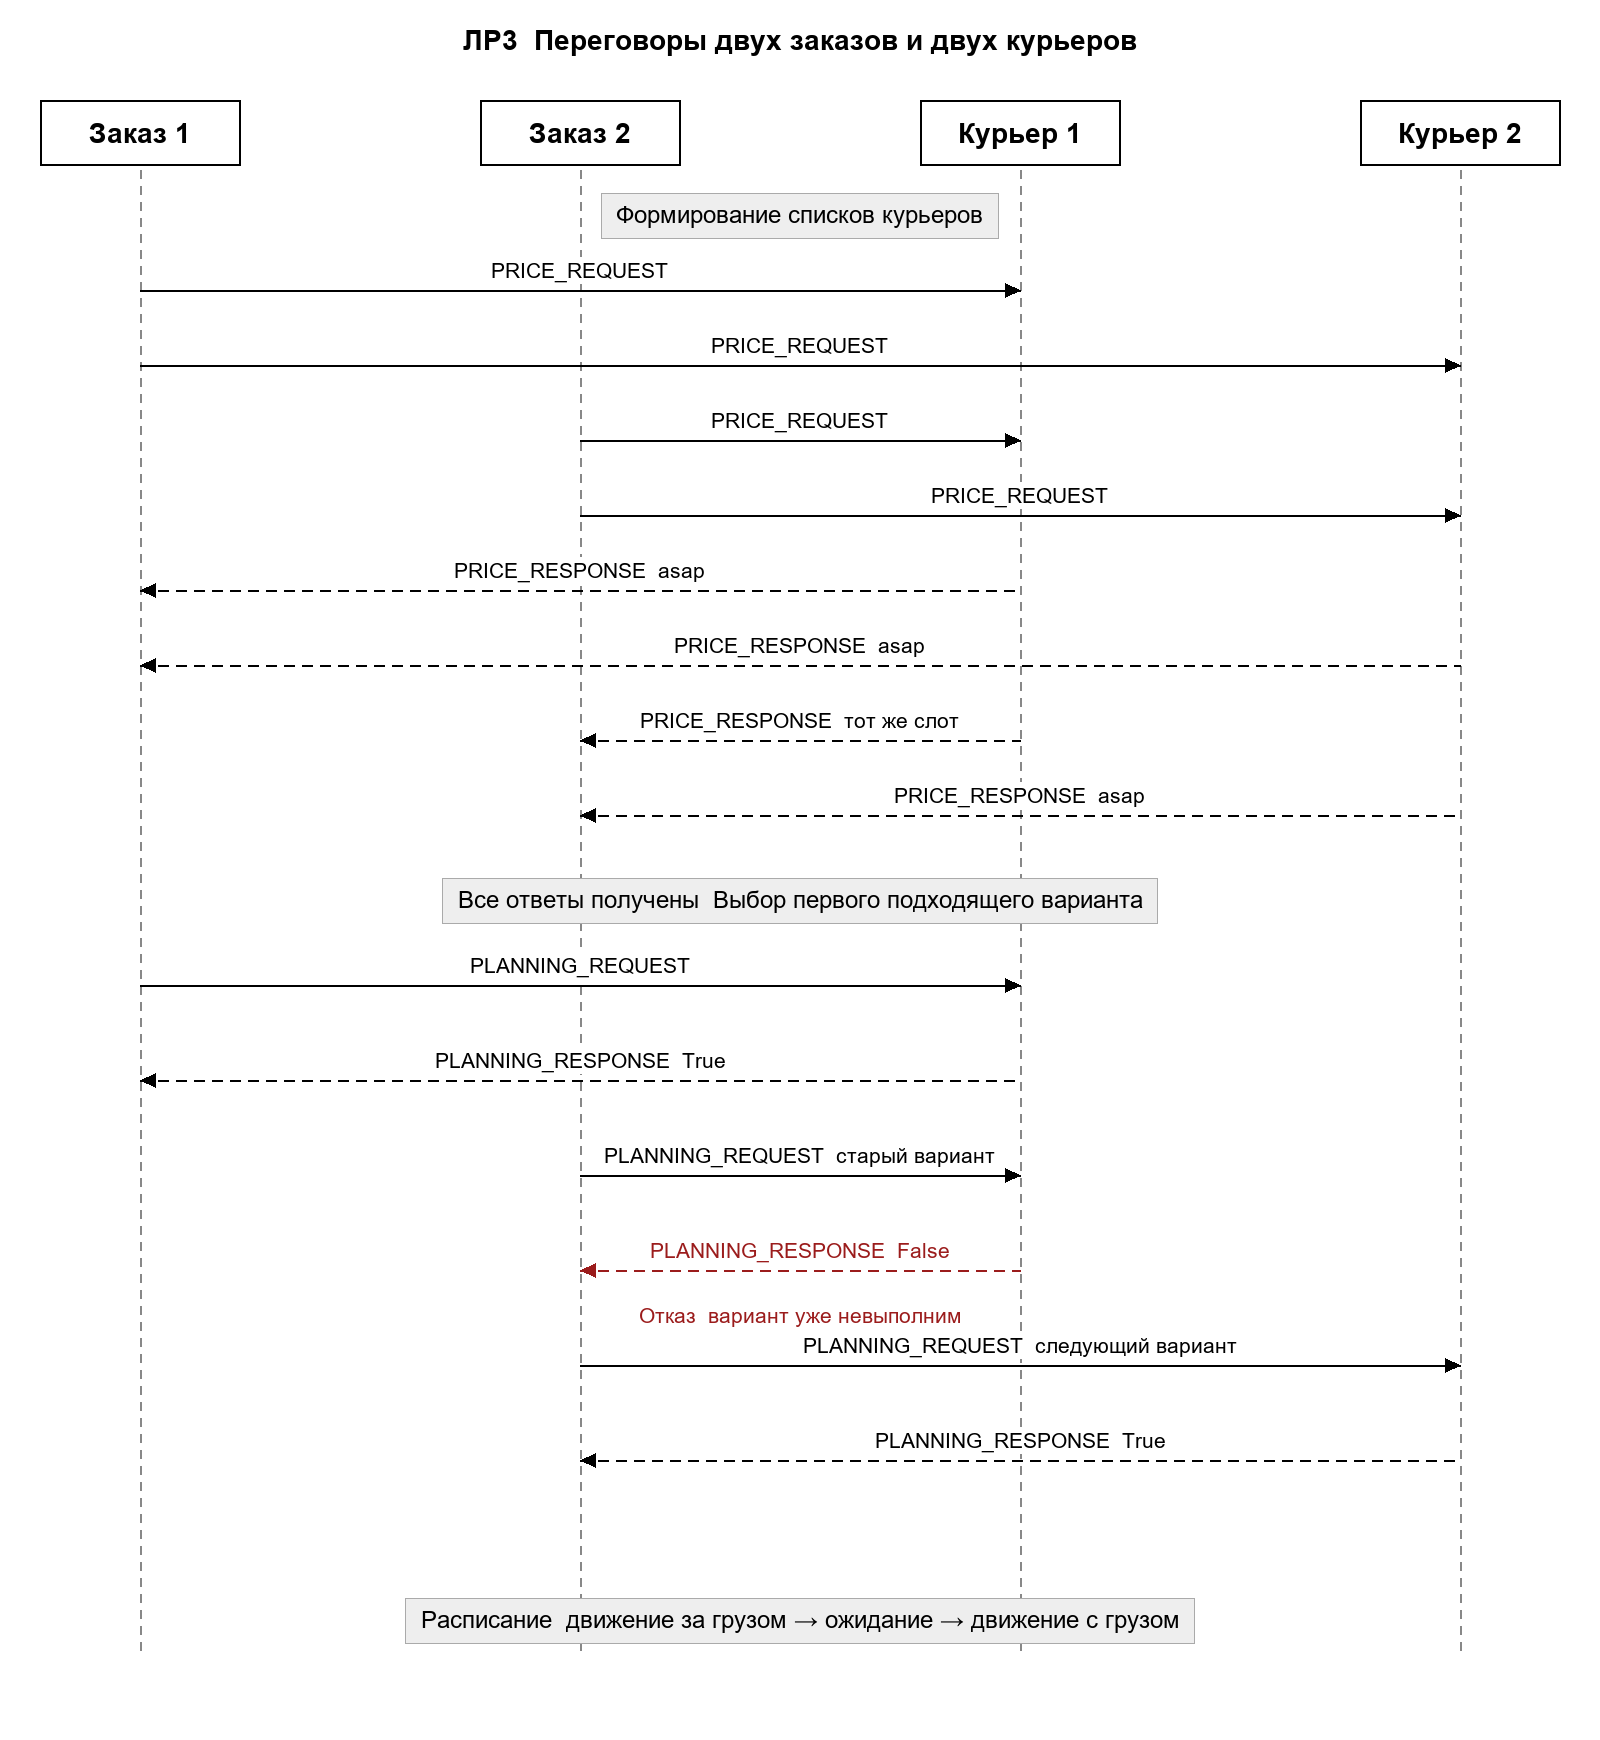

In [19]:
demo_courier = CourierEntity({}, courier_data[0])
demo_orders = [OrderEntity({}, row) for row in order_data[:2]]
offers = [demo_courier.get_variants(order)[0] for order in demo_orders]
for offer in offers:
    accepted = demo_courier.add_order_to_schedule(
        offer['order'], offer['time_from'], offer['time_to'], offer['price'], offer)
    print('Заказ', offer['order'].number, 'принят:', accepted)
print('Пересечения [0, 2):', [item.rec_type for item in demo_courier.get_conflicts(0, 2)])


Заказ 1 принят: True
Заказ 2 принят: False
Пересечения [0, 2): ['Движение за грузом', 'Ожидание']


## 7 Эксперимент на 50 заказах и 20 курьерах

Данные генерируются с `random.Random(3)`: один набор используется в обоих режимах. Все курьеры совместимы с грузами, чтобы сравнивать число сообщений. Первый режим опрашивает всех 20 курьеров, второй — трех ближайших. Оба запуска начинают с пустых расписаний. Близость определяется геометрически, без учета времени освобождения курьера.

In [20]:
"""СР3: 50 заказов, 20 курьеров, опрос всех и трех ближайших."""

import csv
import random
from pathlib import Path



def make_experiment_data():
    rng = random.Random(3)
    couriers = [
        {'Табельный номер': i, 'ФИО': f'Курьер {i}',
         'Координата начального положения x': rng.randint(0, 100),
         'Координата начального положения y': rng.randint(0, 100),
         'Типы доставляемых заказов': 'Посылка', 'Стоимость выхода на работу': 0,
         'Цена работы за единицу времени': 1, 'Скорость': 10,
         'Объем ранца': 10, 'Грузоподъемность': 10}
        for i in range(1, 21)]
    orders = [
        {'Номер': i, 'Наименование': f'Заказ {i}', 'Масса': 1, 'Объем': 1, 'Стоимость': 100,
         'Координата получения x': rng.randint(0, 100),
         'Координата получения y': rng.randint(0, 100),
         'Координата доставки x': rng.randint(0, 100),
         'Координата доставки y': rng.randint(0, 100),
         'Время получения заказа': 0, 'Время доставки заказа': 10000, 'Тип заказа': 'Посылка'}
        for i in range(1, 51)]
    return couriers, orders


def run_experiment(filename='Отчёты/Эксперимент_ЛР3.csv'):
    couriers, orders = make_experiment_data()
    rows = []
    for count in (None, 3):
        scene, counters = plan_orders(couriers, orders, count)
        row = {'Режим': 'Все 20 курьеров' if count is None else '3 ближайших',
               'Заказов': len(orders), 'Курьеров': len(couriers)}
        row.update({kind.value: counters.get(kind.value, 0) for kind in MessageType
                    if kind != MessageType.INIT_MESSAGE})
        row['Всего сообщений'] = sum(counters.values())
        row['Назначено заказов'] = sum(o.assigned_courier is not None
                                      for o in scene.get_entities_by_type('ORDER'))
        rows.append(row)
        print(row)
    with open(filename, 'w', encoding='utf-8-sig', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]), delimiter=';')
        writer.writeheader()
        writer.writerows(rows)
    return rows


In [21]:
experiment_rows = run_experiment()
reduction = 100 * (1 - experiment_rows[1]['Всего сообщений'] / experiment_rows[0]['Всего сообщений'])
print(f'Сокращение числа сообщений: {reduction:.2f}%')


{'Режим': 'Все 20 курьеров', 'Заказов': 50, 'Курьеров': 20, 'Запрос параметров': 1000, 'Ответ с параметрами': 1000, 'Запрос планирования': 50, 'Результат планирования': 50, 'Всего сообщений': 2100, 'Назначено заказов': 50}
{'Режим': '3 ближайших', 'Заказов': 50, 'Курьеров': 20, 'Запрос параметров': 150, 'Ответ с параметрами': 150, 'Запрос планирования': 50, 'Результат планирования': 50, 'Всего сообщений': 400, 'Назначено заказов': 50}
Сокращение числа сообщений: 80.95%


Получено **2100** сообщений при опросе всех и **400** при опросе трех ближайших, сокращение — **80,95%**, или в **5,25 раза**. В обоих режимах назначены 50 заказов. При отсутствии отказов число сообщений равно `2 × N × K + 2 × N`: запросы и ответы параметров плюс запросы и подтверждения планирования. При отказах обмен увеличивается. Ограничение списка снижает обмен, но может исключить подходящего курьера; улучшение цены или сроков этим экспериментом не доказано.

## 8 Ответы на контрольные вопросы

**1 Опишите постановку задачи логистической компании**

Нужно распределить заказы между курьерами и построить последовательность их перемещений. Заказ задает груз, точки получения и доставки и желаемое время. Курьер имеет начальную точку, скорость, ставку, ограничения по массе, объему и типам груза. Расстояния евклидовы, время отсчитывается от t0.

**2 Определите основные классы агентов и их цели**

OrderAgent представляет заказ и ищет исполнителя. CourierAgent представляет курьера, рассчитывает доступный вариант и подтверждает включение заказа в расписание. Диспетчер создает агентов и ведет адресную книгу; решение о назначении принимают сами агенты.

**3 Что такое сцена и почему прямой доступ допустим только в учебной задаче**

Scene хранит сущности, сгруппированные по типам. Заказ получает из нее курьеров, а агент работает со своей сущностью. Прямой доступ упрощает учебную систему в одном процессе. В распределенной системе общая память недоступна, а несогласованные изменения требуют обмена сообщениями и управления доступом.

**4 Как формируется протокол и какие четыре такта в нем используются**

Типы сообщений задают запросы, ответы и реакции участников. Заказ получает список курьеров, рассылает PRICE_REQUEST, курьеры рассчитывают варианты и возвращают PRICE_RESPONSE, затем заказ посылает PLANNING_REQUEST и получает подтверждение или отказ PLANNING_RESPONSE.

**5 Почему заказ ждет всех ответов**

Это позволяет рассмотреть все предложения опрошенных курьеров, включая пустые ответы, и только после этого выбрать вариант. Согласие на первый ответ делает результат зависимым от скорости доставки сообщений и может исключить более подходящие предложения. В ЛР3 оптимизация еще не выполняется.

**6 Почему решение зависит от порядка обработки заказов**

Каждое подтверждение изменяет последнюю точку и время курьера. Следующие заказы получают другие варианты, а ранее выданное предложение может устареть. При перестановке заказов расписание меняется; глобальная оптимальность этим протоколом не гарантируется.

## Вывод

Создана мультиагентная система планирования с чтением Excel, переговорами и сохранением расписания. Выполнены все три задания самостоятельной работы. Полученное решение зависит от порядка заказов и не гарантирует оптимальность.